# 宇宙紫外線背景の検証計算

Faucher-Giguère (2020) の宇宙紫外線背景（FG20）を使い、遮蔽による率の減衰、H・He の電離、二次電離、円盤ガスの冷却と熱化学への影響を調べます。EQCLib のルートで次を実行してから、全セルを実行してください。

```sh
make -C test uvb-data
```

既定では `data/FG20/fg20_cloudy.ascii` を使います。別のディレクトリに置いた場合は `UVB_DIR` で指定します。計算済みの結果を使う場合は、最初のコードセルの `run_dir` を変更してください。 [FG20 の入手と検証条件](../test/README.md#fg20-の遮蔽と計算時間)

In [1]:
%matplotlib inline

import sys
from pathlib import Path

from IPython.display import display
import matplotlib.pyplot as plt

cwd = Path.cwd()
repo_root = next(
    (path for path in (cwd, *cwd.parents)
     if (path / "test" / "uvb" / "UVBackgroundReference.c").is_file()),
    None,
)
if repo_root is None:
    raise FileNotFoundError("EQCLib のリポジトリ内からノートブックを実行してください。")

run_dir = repo_root / "test" / "out" / "uvb"
soft_xray = False  # 円盤試験で軟 X 線ありの対照を描く場合は True
history_density = 0.01  # cm⁻³。円盤格子の密度から選ぶ

plot_dir = str(repo_root / "plot")
if plot_dir not in sys.path:
    sys.path.insert(0, plot_dir)

from plot_style import PLOT_STYLE
from plot_uvb import (
    load_results, plot_cooling_curve, plot_disk_cooling, plot_disk_grid,
    plot_disk_history, plot_equilibrium, plot_secondaries, plot_shielding,
)

try:
    results = load_results(run_dir)
except FileNotFoundError as error:
    raise FileNotFoundError(
        f"{run_dir} に必要な出力がありません。EQCLib のルートで make -C test uvb-data を実行してください。"
    ) from error

print(f"H・He 平衡 {len(results['equilibrium'])} 条件、円盤 {len(results['disk_grid'])} 条件")
print(f"円盤の更新履歴 {len(results['disk_history'])} 点")

No event loop hook running.
H・He 平衡 36 条件、円盤 144 条件
円盤の更新履歴 1728 点


## 平板内での遮蔽

片側の H I 柱密度に対する H I・He I・He II の一次光電離率と、H I 由来の光電子の運動エネルギー供給率を、各赤方偏移の無遮蔽値で規格化します。角度平均した半球あたりの率を使い、金属量は `Z = 0` です。光電離率とエネルギー供給率が異なる割合で減衰する様子から、透過したスペクトルの硬化を確認できます。

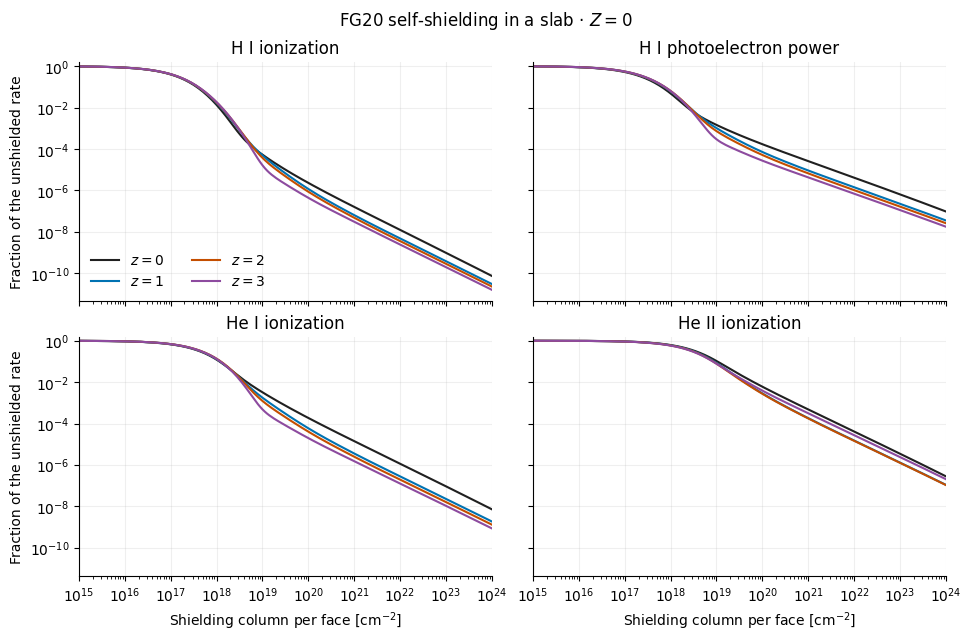

In [2]:
with plt.rc_context(PLOT_STYLE):
    fig = plot_shielding(results['shielding'])
    display(fig)
    plt.close(fig)

## 固定温度での H・He の化学平衡

無遮蔽の FG20 で、温度を `10⁴ K` に固定した各密度の電離分率です。実線は EQCLib の平衡計算、丸印は H・He の定常反応比と電荷保存から独立に求めた参照値です。

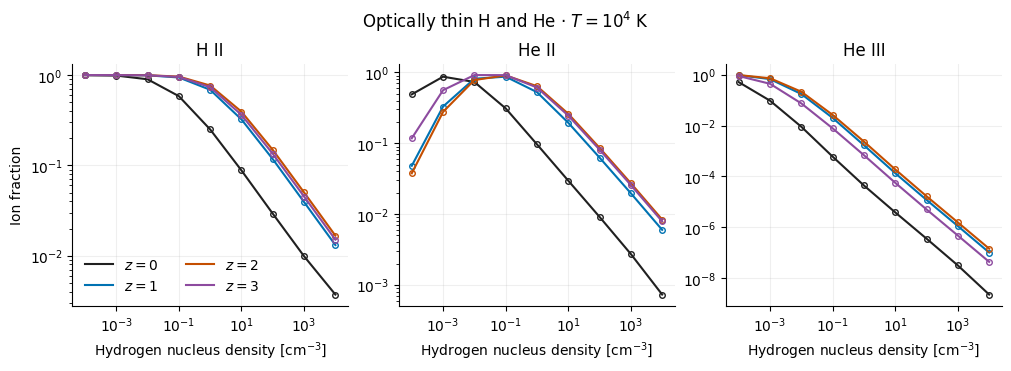

In [3]:
with plt.rc_context(PLOT_STYLE):
    fig = plot_equilibrium(results['equilibrium'])
    display(fig)
    plt.close(fig)

## 光電子の加熱と二次電離

水素の電離分率を `0.01`、金属量を `0` に固定します。左は光電子の運動エネルギー供給のうち熱に回る割合、右は H I の一次・二次電離率の和を一次電離率で割った値です。FG20 全域と、入射光子の上限を `300 eV` にした場合を比較します。

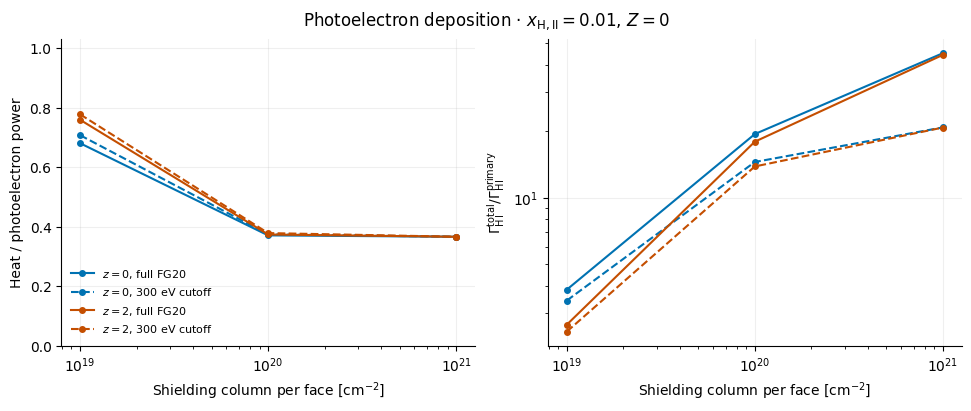

In [4]:
with plt.rc_context(PLOT_STYLE):
    fig = plot_secondaries(results['secondary'])
    display(fig)
    plt.close(fig)

## 円盤ガスの温度と電離

太陽金属量、`G0 = 0.1`、`X0 = 1`、宇宙線ありの円盤格子を、1 Myr 刻みで12回更新した結果です。UVB の有無と平衡・非平衡を同じ密度で比較します。`soft_xray` を切り替えると、軟 X 線の条件をそろえた別の組を表示できます。

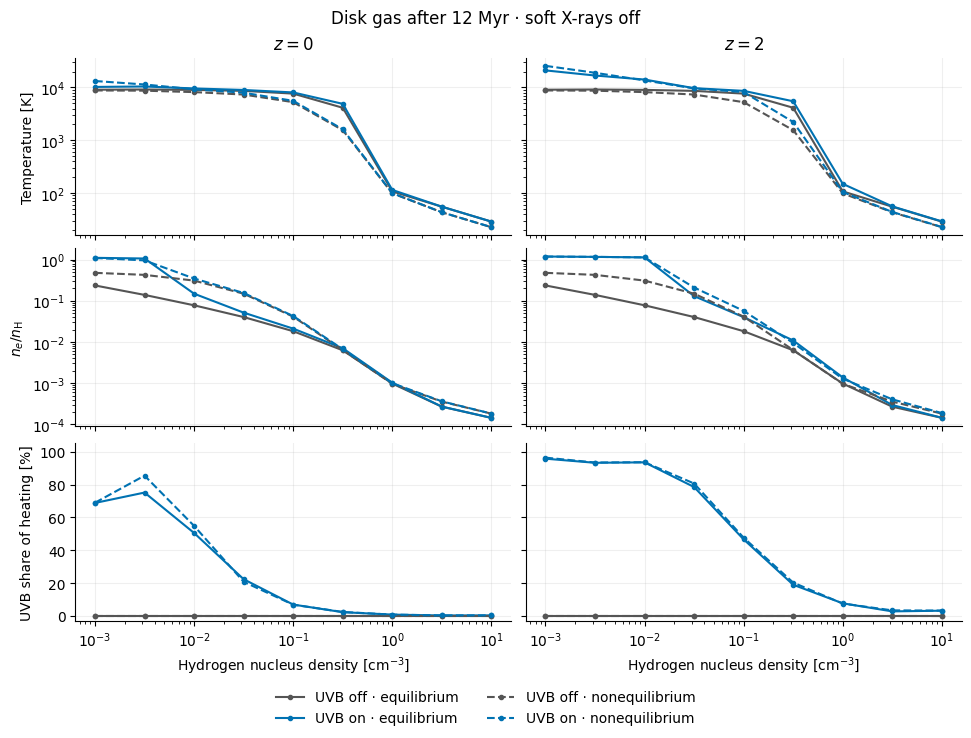

In [5]:
with plt.rc_context(PLOT_STYLE):
    fig = plot_disk_grid(results['disk_grid'], soft_xray=soft_xray)
    display(fig)
    plt.close(fig)

## UVB の有無による円盤ガスの冷却率

上段は12 Myr 後の全冷却率 `L_tot`、下段は同じ密度・赤方偏移・化学モードで UVB オンの冷却率をオフの冷却率で割った値です。比が1より大きい点は UVB オンで冷却率が高くなっています。この比較には、熱化学更新で生じた温度と組成の違いも含まれます。

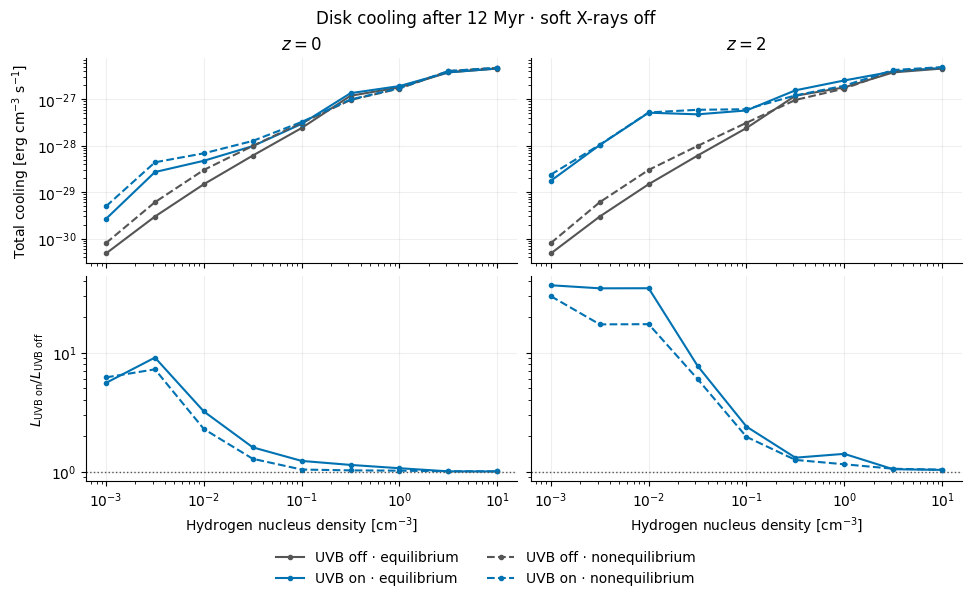

In [6]:
with plt.rc_context(PLOT_STYLE):
    fig = plot_disk_cooling(results['disk_grid'], soft_xray=soft_xray)
    display(fig)
    plt.close(fig)

## 密度・遮蔽柱密度を固定した冷却曲線

`nH = 0.01 cm⁻³`、上下それぞれの遮蔽柱密度 `10¹⁸ cm⁻²`、太陽金属量 `Z = 0.0134` で、`10²〜10⁶ K` を走査します。各温度で UVB オン・オフそれぞれの化学平衡組成を求め、同じ温度での体積あたりの全冷却率 `L_tot` を比較します。

上段は全冷却率、下段は UVB オンをオフで割った値です。左が `z = 0`、右が `z = 2` です。`soft_xray` を切り替えると、軟 X 線ありの比較も表示できます。

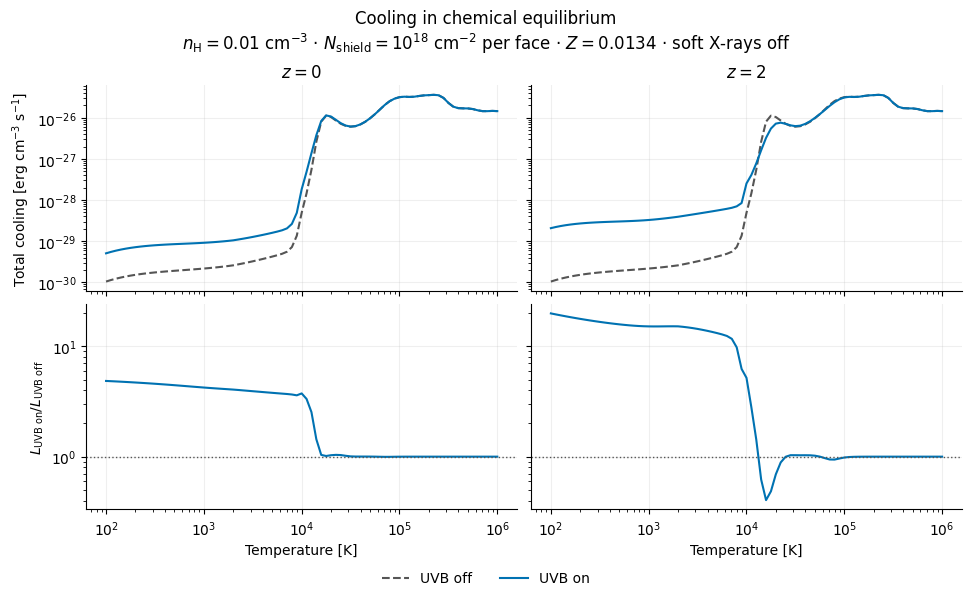

In [7]:
with plt.rc_context(PLOT_STYLE):
    fig = plot_cooling_curve(results['cooling_curve'], soft_xray=soft_xray)
    display(fig)
    plt.close(fig)

## 円盤ガスの更新履歴

`history_density` で指定した密度の温度、H II 分率、各更新に渡した片側の遮蔽柱密度を示します。柱密度は全水素核密度に100 pc と前ステップの中性水素核分率 `xHI + 2*xH2` を掛けて求めます。各点は1回目以降の受理済みステップです。

初期温度は全条件で `8000 K` です。平衡モードは各照射条件で求めた無遮蔽の化学平衡から、非平衡モードは H II 分率 `0.5` から始めます。

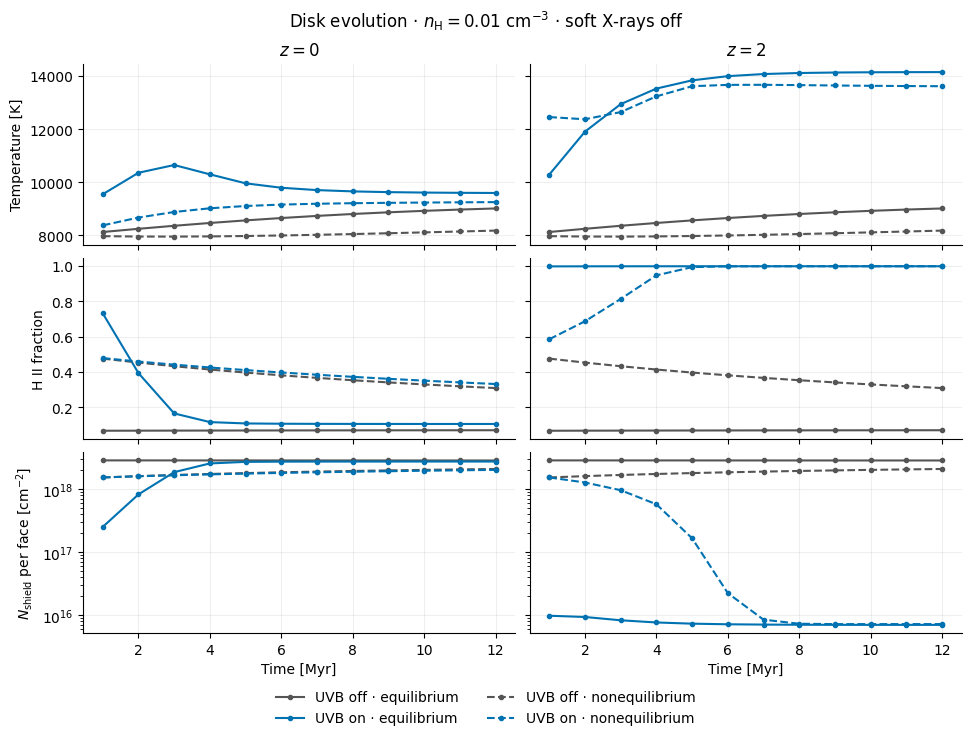

In [8]:
with plt.rc_context(PLOT_STYLE):
    fig = plot_disk_history(results['disk_history'], density=history_density, soft_xray=soft_xray)
    display(fig)
    plt.close(fig)